# Weather and traffic-impact severity — CSV only

## 1. Load the needed columns

In [1]:
# Pandas handles the table; Matplotlib makes the chart.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('../data/US_Accidents_March23_sampled_500k.csv')
accidents = pd.read_csv(
    csv_path, usecols=['Weather_Condition', 'Severity', 'Source'], low_memory=False
)
print('Accident rows:', len(accidents))
print('Missing weather labels:', accidents['Weather_Condition'].isna().sum())
print('Missing severity ratings:', accidents['Severity'].isna().sum())
print('Accident data sources:')
display(accidents['Source'].value_counts())

Accident rows: 500000
Missing weather labels: 11101
Missing severity ratings: 0
Accident data sources:


Source
Source1    279623
Source2    214044
Source3      6333
Name: count, dtype: int64

## 2. Select common weather labels

In [2]:
# Count exact labels and keep the 12 most common.
top_weather = accidents['Weather_Condition'].value_counts().head(12)
weather_order = top_weather.index.tolist()
display(top_weather.rename('Accident records'))

# Rating 3 or 4 means greater traffic impact in this dataset.
selected = accidents.loc[accidents['Weather_Condition'].isin(weather_order)].copy()
selected['Higher traffic impact'] = selected['Severity'].isin([3, 4])
print('Rows in the 12 weather groups:', len(selected))

Weather_Condition
Fair                166053
Mostly Cloudy        65398
Cloudy               53107
Clear                52379
Partly Cloudy        45125
Overcast             24901
Light Rain           22718
Scattered Clouds     13030
Light Snow            8233
Fog                   6445
Rain                  5501
Haze                  4967
Name: Accident records, dtype: int64

Rows in the 12 weather groups: 467857


## 3. Count accidents and calculate percentages

In [3]:
# First show the pooled totals, then the breakdown by source.
overall = selected.groupby('Weather_Condition')['Higher traffic impact'].agg(
    accidents='size', severity_3_or_4='sum'
).reindex(weather_order)
overall['percent_3_or_4'] = (
    100 * overall['severity_3_or_4'] / overall['accidents']
).round(1)

by_source = selected.groupby(['Weather_Condition', 'Source'])['Higher traffic impact'].agg(
    accidents='size', severity_3_or_4='sum'
).reset_index()
by_source['percent_3_or_4'] = (
    100 * by_source['severity_3_or_4'] / by_source['accidents']
).round(1)

print('All sources combined:')
display(overall)
print('Each source separately:')
display(by_source.sort_values(['Source', 'accidents'], ascending=[True, False]))

# Check that our groups account for every selected accident.
assert overall['accidents'].sum() == len(selected)
assert by_source['accidents'].sum() == len(selected)

All sources combined:


,accidents,severity_3_or_4,percent_3_or_4
Weather_Condition,,,
Fair,166053,19783,11.9
Mostly Cloudy,65398,13730,21.0
Cloudy,53107,7514,14.1
Clear,52379,17820,34.0
Partly Cloudy,45125,9249,20.5
Overcast,24901,8754,35.2
Light Rain,22718,5111,22.5
Scattered Clouds,13030,4541,34.9
Light Snow,8233,1686,20.5


Each source separately:


,Weather_Condition,Source,accidents,severity_3_or_4,percent_3_or_4
6,Fair,Source1,116888,5182,4.4
3,Cloudy,Source1,35716,2056,5.8
21,Mostly Cloudy,Source1,34842,2915,8.4
27,Partly Cloudy,Source1,24099,1989,8.3
15,Light Rain,Source1,12198,1129,9.3
0,Clear,Source1,11752,3753,31.9
24,Overcast,Source1,5807,2051,35.3
18,Light Snow,Source1,5286,411,7.8
9,Fog,Source1,3938,219,5.6
30,Rain,Source1,3035,276,9.1


## 4. Compare the two largest sources

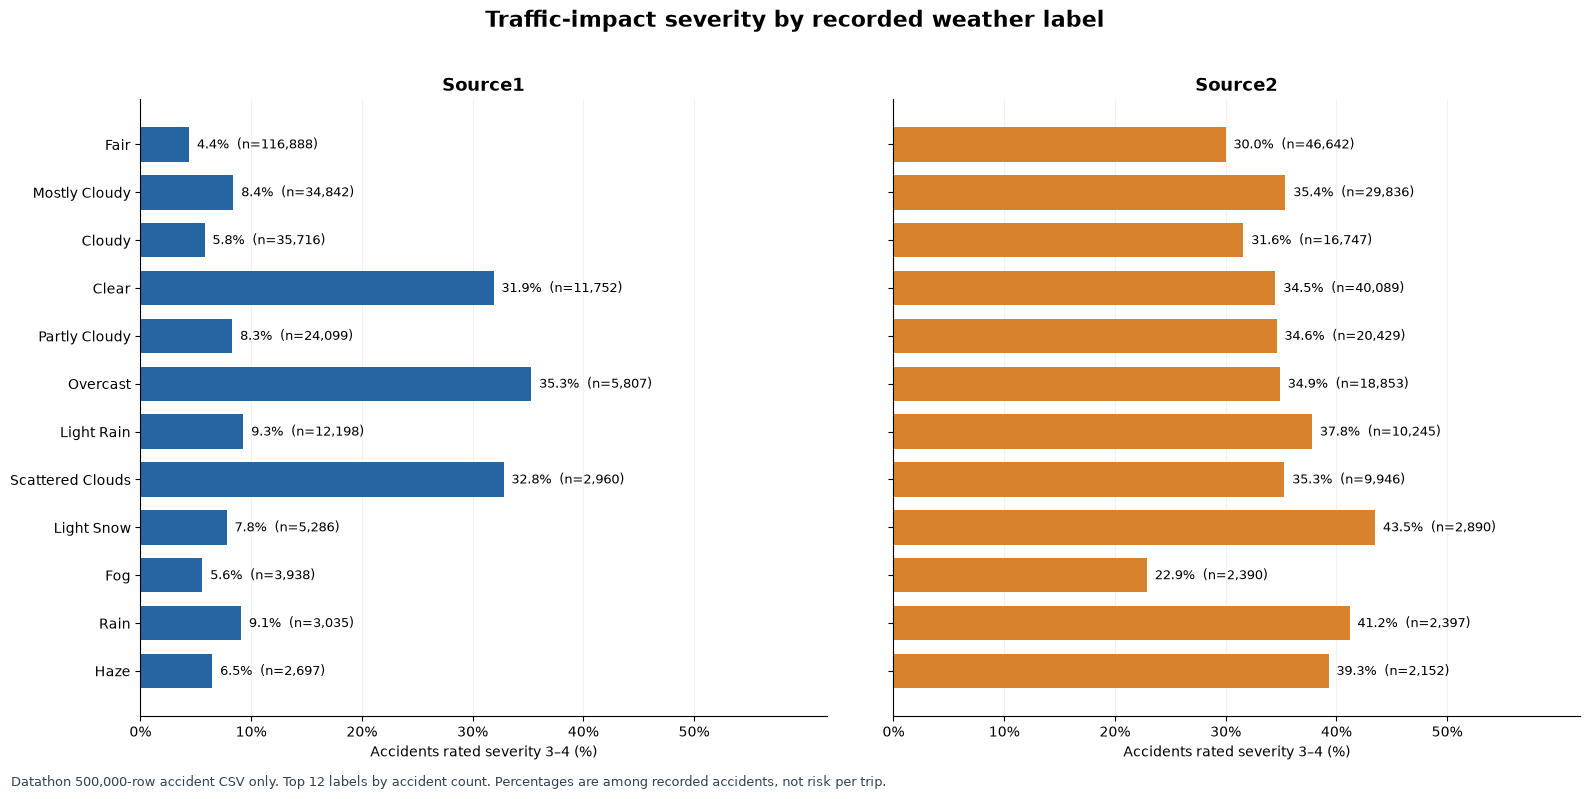

Saved chart: ../charts/weather_severity_by_source.png


In [4]:
# Use the same weather order and percentage scale in both panels.
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True)
source_colors = {'Source1': '#2764a2', 'Source2': '#d7832e'}

for ax, source in zip(axes, ['Source1', 'Source2']):
    rows = (by_source.loc[by_source['Source'] == source]
            .set_index('Weather_Condition').reindex(weather_order))
    bars = ax.barh(weather_order, rows['percent_3_or_4'],
                   color=source_colors[source], height=0.72)
    ax.set_xlim(0, 62)
    ax.set_title(source, fontsize=13, weight='bold')
    ax.set_xlabel('Accidents rated severity 3–4 (%)')
    ax.set_xticks([0, 10, 20, 30, 40, 50],
                  labels=['0%', '10%', '20%', '30%', '40%', '50%'])
    ax.grid(axis='x', alpha=0.17)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    for bar, row in zip(bars, rows.itertuples()):
        ax.text(bar.get_width() + 0.7,
                bar.get_y() + bar.get_height()/2,
                f'{row.percent_3_or_4:.1f}%  (n={row.accidents:,})',
                va='center', fontsize=9)

axes[0].invert_yaxis()
axes[1].tick_params(axis='y', labelleft=False)
fig.suptitle('Traffic-impact severity by recorded weather label',
             fontsize=16, weight='bold', y=1.02)
fig.text(0.01, -0.015,
         'Datathon 500,000-row accident CSV only. Top 12 labels by accident count. Percentages are among recorded accidents, not risk per trip.',
         fontsize=9, color='#334155')
fig.tight_layout(w_pad=4)
chart_path = Path('../charts/weather_severity_by_source.png')
chart_path.parent.mkdir(exist_ok=True)
fig.savefig(chart_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved chart:', chart_path)